# Project work, part 2 - Data Sources

## Link to Github: https://github.com/Rita-HT/IND320-reservoir
## Link to Streamlit: https://ind320reservoir.streamlit.app/
## Screencast uploaded on Github

*26.10.2026* : The notebook and GitHub have been updated since the deadline. A screencast has also been uploaded to GitHub.  

## Updates regarding GitHub:

At first, the code was written directly on the different pages to complete Project 2, on the main branch. However, the assignment required the use of branches in GitHub. A branch was then created to upload the Notebook, as well as delete 4_test.py as it was unnecessary and other small updates to the pages.

## Setup - imports libaries, Spark, prints versions and file paths

The code imports the necessary libraries needed to complete this project, configure Spark to use the same Python installation as the notebook, and prints out the versions and file paths to verify the environment.

In [117]:
#import libaries needed
import sys
import os
import pyspark
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pathlib import Path
from pyspark.sql import SparkSession
from cassandra.cluster import Cluster
from getpass import getpass
from pymongo import MongoClient

# Tests if Spark workers use the same Python as the notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Prints out the versions and file paths 
print("Python:", sys.executable)
print("PySpark:", pyspark.__version__)
print("Pandas:", pd.__version__)
print("Worker Python:", os.environ["PYSPARK_PYTHON"])

Python: C:\Users\RitaH\anaconda3\envs\ind320_env\python.exe
PySpark: 3.5.1
Pandas: 3.0.6
Worker Python: C:\Users\RitaH\anaconda3\envs\ind320_env\python.exe


## Set up - Java, Hadoop, Spark
The code sets up Java, Hadoop, and the network so that Spark can function correctly on Windows, and verifies that the necessary files are present. It then starts Spark and connects it to Cassandra, enabling us to work with data. And finally, a test to verify that Spark works.

In [13]:
# Set up Java and Hadoop
os.environ["JAVA_HOME"] = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + r"C:\hadoop\bin;" + os.environ["PATH"]

# Check and tests Hadoop setup
print("Hadoop:", os.environ["HADOOP_HOME"])
print("Winutils exists:", Path(r"C:\hadoop\bin\winutils.exe").exists())

# Start Spark
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("IND320")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.extraJavaOptions", "-Dhadoop.home.dir=C:/hadoop")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .getOrCreate()
)

# The time zone in Spark to Coordinated Universal Time (UTC) - handy when data comes from various sources
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Test if Spark can process numbers
numbers = spark.sparkContext.parallelize([10, 20, 30])
result = numbers.map(lambda x: x + 5).collect()
print("Result:", result)  # Should print [15, 25, 35]

Hadoop: C:\hadoop
Winutils exists: True
Result: [15, 25, 35]


## Cassandra
Once it has been verified that Spark can process numbers, Spark is connected to Cassandra. The code checks which version is running and that Spark can read from it. A keyspace is created, together with a table to store data on power transfers: the connection, direction, timestamp and amount of energy.

In [40]:
# Connects to Cassandra
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect()

version = session.execute("SELECT release_version FROM system.local").one()[0]
print("Cassandra version:", version)

# Creates a keyspace, ind320
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

# Creates table to store data on power transfers, entsoe_transfers
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.entsoe_transfers (
        connection text,
        direction text,
        timestamp timestamp,
        energy_mwh double,
        PRIMARY KEY ((connection, direction), timestamp)
    )
""")

# Check that the table exists in the keyspace
tables = session.execute(
    "SELECT table_name FROM system_schema.tables WHERE keyspace_name = 'ind320'"
)
print("Tables in keyspace ind320:", [row.table_name for row in tables])


Cassandra version: 4.1.12
Tables in keyspace ind320: ['entsoe_transfers', 'test']


## Testing the Spark-Cassandra-connection
As part of the assignment, we test that Spark and Cassandra can communicate with each other. We do this by writing some test data to a table in Cassandra and then reading it back using Spark. Once the test is complete, we delete the test table.

In [108]:
# Deletes the old test table and create a new one
session.execute("DROP TABLE IF EXISTS ind320.test")
session.execute("CREATE TABLE ind320.test (id int PRIMARY KEY, name text)")

# Create two test rows using Spark
test_df = spark.createDataFrame([(1, "a"), (2, "b")], ["id", "name"])

# Save the test data to Cassandra
(test_df.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(keyspace="ind320", table="test")
    .save())

# Read the data from Cassandra and display it
(spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="test")
    .load()
    .show())

# Deletes test table when finished
session.execute("DROP TABLE ind320.test")


+---+----+
| id|name|
+---+----+
|  2|   b|
|  1|   a|
+---+----+



## MongoDB
As part of the assignment, the code tests that Python can connect to MongoDB and work with the database. This is done by inserting test data, reading it back, updating it and deleting it. The test checks that all the basic database operations work correctly. The connection string is entered manually and is not saved in the notebook, to keep the login details private.

In [150]:
from getpass import getpass
from pymongo import MongoClient

# Connects to MongoDB
uri = getpass("MongoDB connection string: ")
client = MongoClient(uri, serverSelectionTimeoutMS=10000)
client.admin.command("ping")
print("Connected to MongoDB")

# Select the database and test collection
db = client["ind320"]
test = db["test"]

# Remove old test data
test.delete_many({})

# Insert and read a test document
test.insert_one({"name": "test", "value": 1})
print("Inserted:", test.find_one({"name": "test"}, {"_id": 0}))

# Update the test document
test.update_one({"name": "test"}, {"$set": {"value": 2}})
print("Updated:", test.find_one({"name": "test"}, {"_id": 0}))

# Delete the test document and check the result
test.delete_one({"name": "test"})
print("Documents left:", test.count_documents({}))

MongoDB connection string:  ········


Connected to MongoDB
Inserted: {'name': 'test', 'value': 1}
Updated: {'name': 'test', 'value': 2}
Documents left: 0


## Retrieving Reservoir Data from NVE
The code fetches the reservoir data from the NVE API using the "HentOffentligData" endpoint. The HTTP status is printed, and the data is converted into a DataFrame named "reservoir_data". The number of rows and columns and the first five rows are shown to check the data

In [17]:
# Public reservoir data from the NVE API
api_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Send a request to the API
response = requests.get(
    f"{api_url}/HentOffentligData",
    timeout=60
)

# Check the response status
print("HTTP status:", response.status_code) #Should show HTTP status: 200
response.raise_for_status()

# Convert data into a DF
reservoir_data = pd.DataFrame(response.json())

# Display shape of dataset
print("Rows:", reservoir_data.shape[0], "| Columns:", reservoir_data.shape[1])

# Shows five rows
reservoir_data.head()


HTTP status: 200
Rows: 14931 | Columns: 11


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [135]:
# Get the list of areas from the API
response_areas = requests.get(f"{api_url}/HentOmråder", timeout=60)
response_areas.raise_for_status()
areas_json = response_areas.json()[0]

# Put the areas from the three lists (land, elspot, vassdrag) into one df
areas = pd.concat(
    [pd.DataFrame(areas_json[key]) for key in ["land", "elspot", "vassdrag"]],
    ignore_index=True
)

# Prints the number rows and counts areatypes
print(areas.shape)
print(areas["omrType"].value_counts())

# Display the table
areas


(10, 5)
omrType
EL      5
VASS    4
NO      1
Name: count, dtype: int64


,navn,navn_langt,beskrivelse,omrType,omrnr
0,Norge,Norge,Hele landet,NO,0
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


In [21]:
# Check missing values in each column
print(reservoir_data.isna().sum())

dato_Id                     0
omrType                     0
omrnr                       0
iso_aar                     0
iso_uke                     0
fyllingsgrad                0
kapasitet_TWh               0
fylling_TWh                 0
neste_Publiseringsdato      0
fyllingsgrad_forrige_uke    0
endring_fyllingsgrad        0
dtype: int64


In [23]:
# Change the Norwegian column names to English names for readability
rename_map = {
    "dato_Id": "Date", "omrType": "Area_type", "omrnr": "Area_number",
    "iso_aar": "Iso_yr", "iso_uke": "Iso_week", "fyllingsgrad": "Fill_lvl",
    "kapasitet_TWh": "Capacity_TWh", "fylling_TWh": "Fill_TWh",
    "neste_Publiseringsdato": "Nxt_pubDate",
    "fyllingsgrad_forrige_uke": "Fill_lvl_Lstweek",
    "endring_fyllingsgrad": "Diff_Fill_lvl",
}
reservoirs = reservoir_data.rename(columns=rename_map).copy()

# Make the date columns into dates and sorts by date
reservoirs["Date"] = pd.to_datetime(reservoirs["Date"], errors="coerce")
reservoirs["Nxt_pubDate"] = pd.to_datetime(reservoirs["Nxt_pubDate"], errors="coerce")
reservoirs = reservoirs.sort_values("Date").reset_index(drop=True)

# Check the dataset
print("Rows:", len(reservoirs), "| Columns:", reservoirs.shape[1])
print("Period:", reservoirs["Date"].min().date(), "to", reservoirs["Date"].max().date())
print("Area types:", sorted(reservoirs["Area_type"].unique()))

# Check the placeholder date 0001-01-01 in Nxt_pubDate
print("Placeholder dates:", (reservoirs["Nxt_pubDate"].dt.year < 1900).sum())

# Check that the data is weekly: days between observations, in one randomly chosen area
one_area = reservoirs[(reservoirs["Area_type"] == "EL") & (reservoirs["Area_number"] == 1)]
print("Days between observations:", one_area["Date"].diff().dt.days.value_counts().to_dict())

Rows: 14931 | Columns: 11
Period: 1995-01-08 to 2026-10-18
Area types: ['EL', 'NO', 'VASS']
Placeholder dates: 11322
Days between observations: {7.0: 1658}


## Overview of the NVE reservoir data from the API
After fetching the reservoir data from the NVE API, the DataFrame shows that the data set has 14931 rows and 11 columns.The NVE API has 10 areas: Norway, 5 electricity areas, and 4 water areas. It is structured as weekly time-series data of the reservoir filling in Norwegian areas: EL (electricity price areas), NO (the whole of Norway) and VASS (water areas). The data runs from January 1995 to October 2026. There are 7 days between each observation in an area as all 1658 intervals between observations in EL 1 (randomly chosen area) are exactly 7 days, so there are no gaps. In addition, 11322 rows in Nxt_pubDate contain the placeholder date "0001-01-01" as the numbers represents observations that do not have a next publication date. However, the column is not used in the plots, so the placeholder is kept.



## Recreate the associated plots from part 1 of the project using the API connection

In Part 1, the dataset reservoirs.csv was used to create plots of each variable separately, as well as a combined plot showing all variables. Since the variables have different scales, the combined plot was designed to make the data easier to read and compare. In this assignment, the same plots are recreated using data retrieved from the NVE API and stored in the DataFrame reservoirs.

The feedback on Part 1 was that the plots were difficult to interpret because the lines for different areas overlapped, making it hard to distinguish between them. To address this, the plots in this part are organized into separate panels for each area type. This makes the figures clearer and makes it easier to compare changes over time within each area type.

In [34]:
# Define the area types and one colour for each type
area_types = ["EL", "NO", "VASS"]
colors = {"EL": "tab:blue", "NO": "tab:red", "VASS": "tab:green"}


def plot_by_area(column, zero_line=False, same_scale=True):
    # Find all areas (type and number) and sort them
    areas = (
        reservoirs[["Area_type", "Area_number"]]
        .drop_duplicates()
        .sort_values(["Area_type", "Area_number"])
        .values.tolist()
    )

    # Keep only the area types we want to plot
    areas = [area for area in areas if area[0] in area_types]

    # Create a grid of panels with 3 panels in each row
    n_cols = 3
    n_rows = -(-len(areas) // n_cols)  # round up to whole rows
    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(14, 2.6 * n_rows),
        sharex=True,
        sharey=same_scale,
        squeeze=False
    )

    # Loop through each area and its corresponding panel
    for ax, (area_type, area_number) in zip(axes.flat, areas):

        # Filter the dataset to include only the current area, sorted by date
        data = reservoirs[
            (reservoirs["Area_type"] == area_type)
            & (reservoirs["Area_number"] == area_number)
        ].sort_values("Date")

        # Plot the chosen column as one line, coloured by area type
        ax.plot(
            data["Date"],
            data[column],
            linewidth=0.6,
            color=colors[area_type]
        )

        # Add a horizontal zero line if requested
        if zero_line:
            ax.axhline(0, color="black", linewidth=0.6)

        # Set the panel title and add a light grid
        ax.set_title(f"{area_type} {area_number}", fontsize=10)
        ax.grid(True, alpha=0.3)

    # Hide the empty panels at the end of the grid
    for ax in axes.flat[len(areas):]:
        ax.set_visible(False)

    # Add a title for the whole figure
    fig.suptitle(column, fontsize=13)

    # Adjust the layout to prevent overlapping elements
    fig.tight_layout(rect=(0, 0, 1, 0.97))

    # Display the figure
    plt.show()

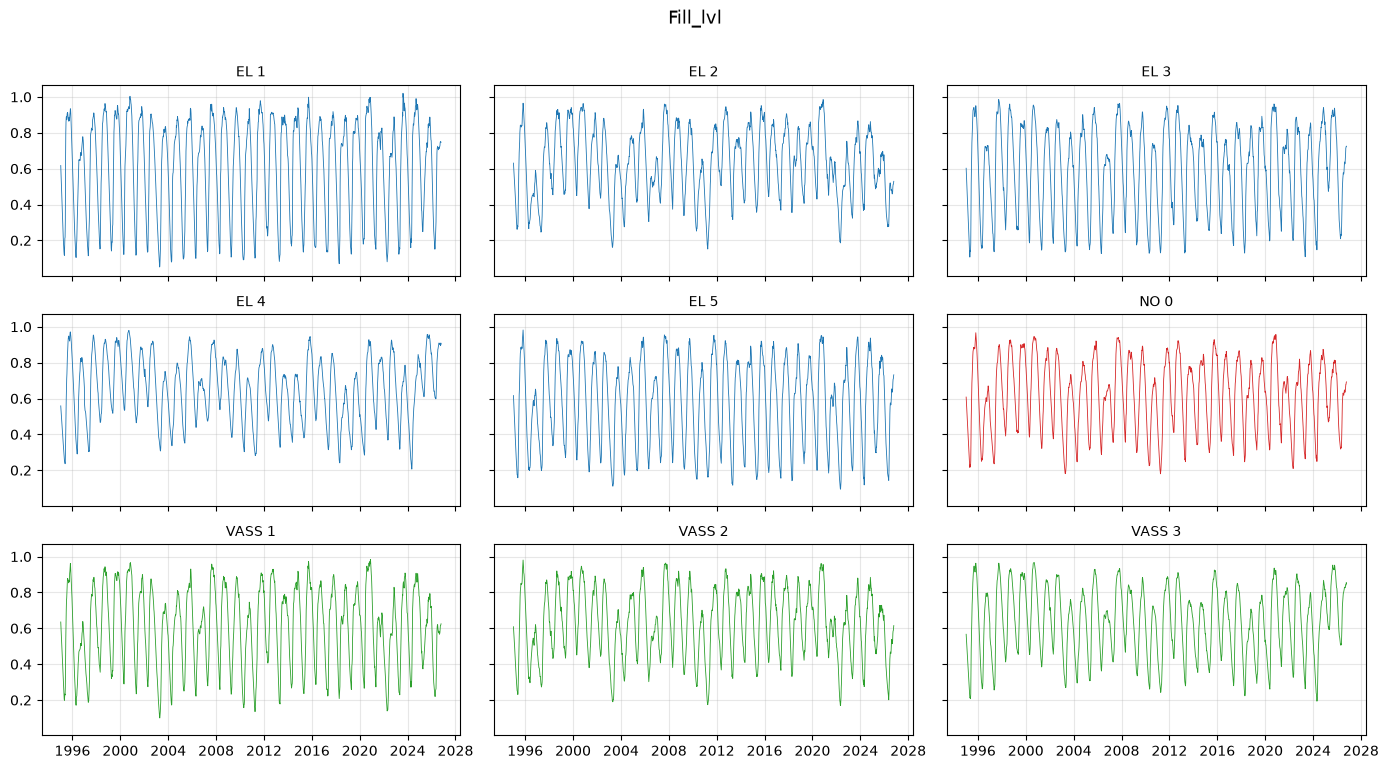

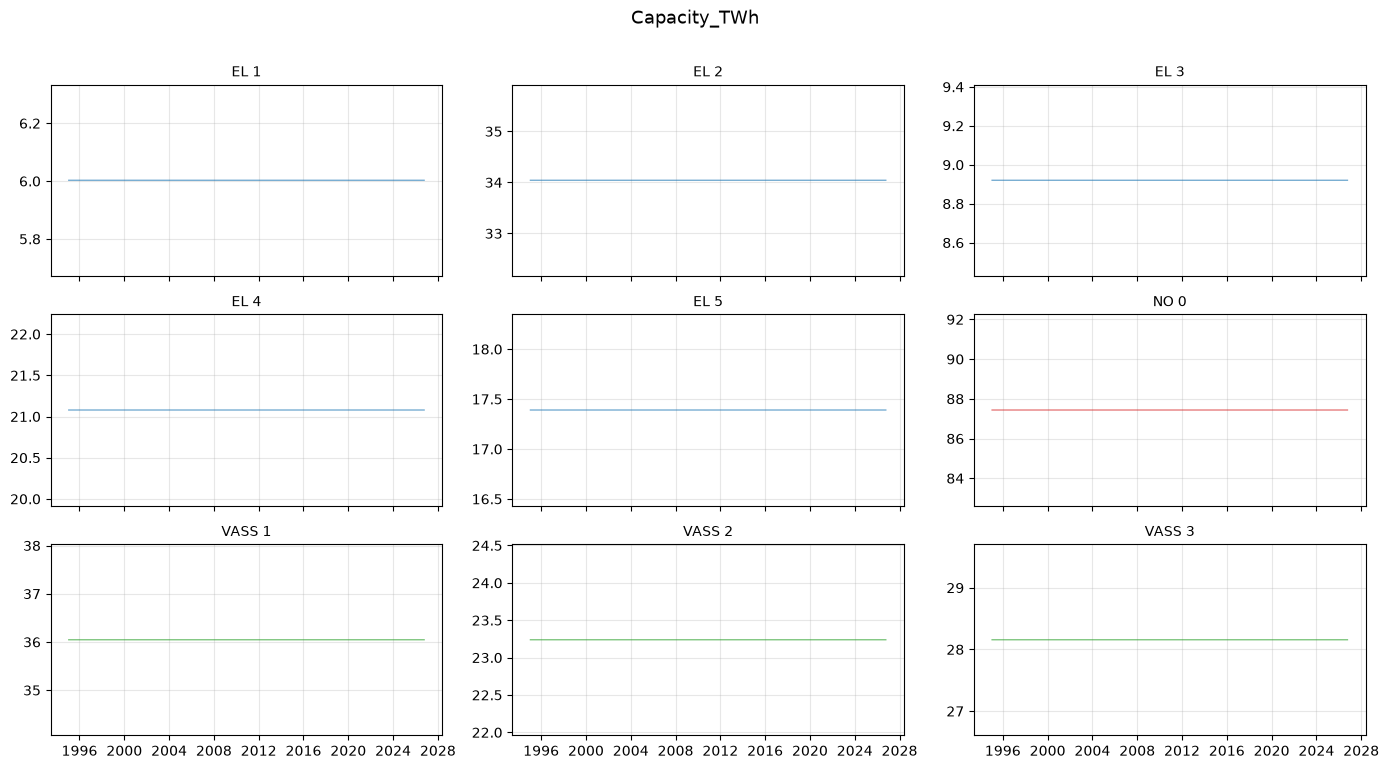

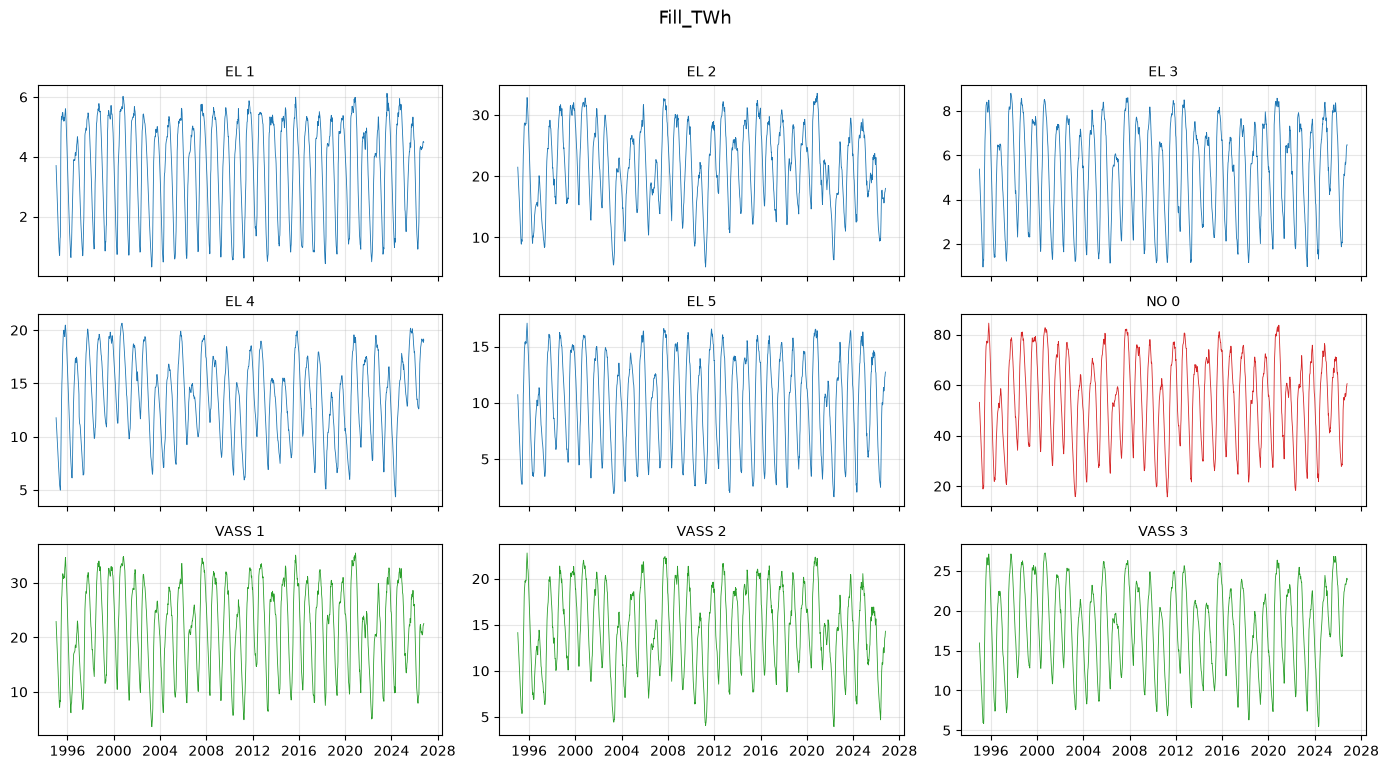

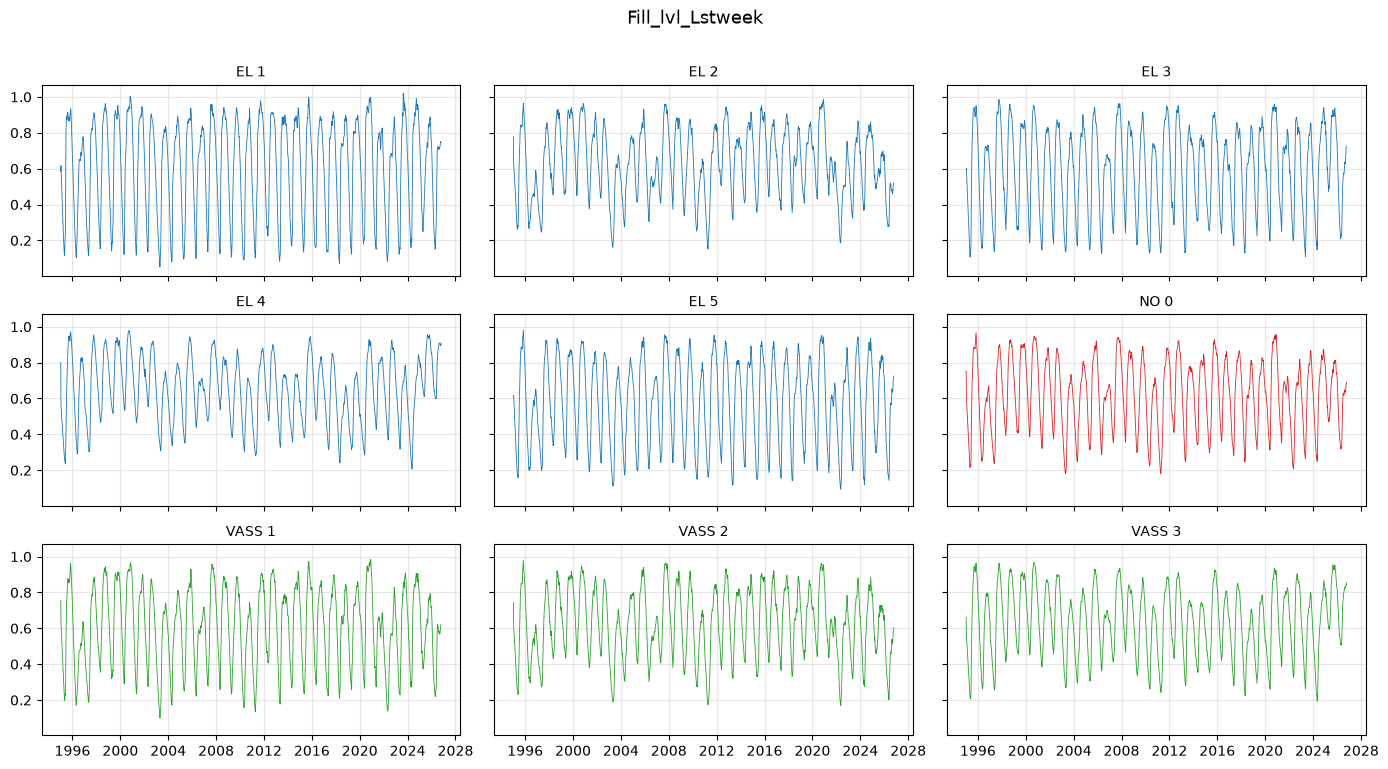

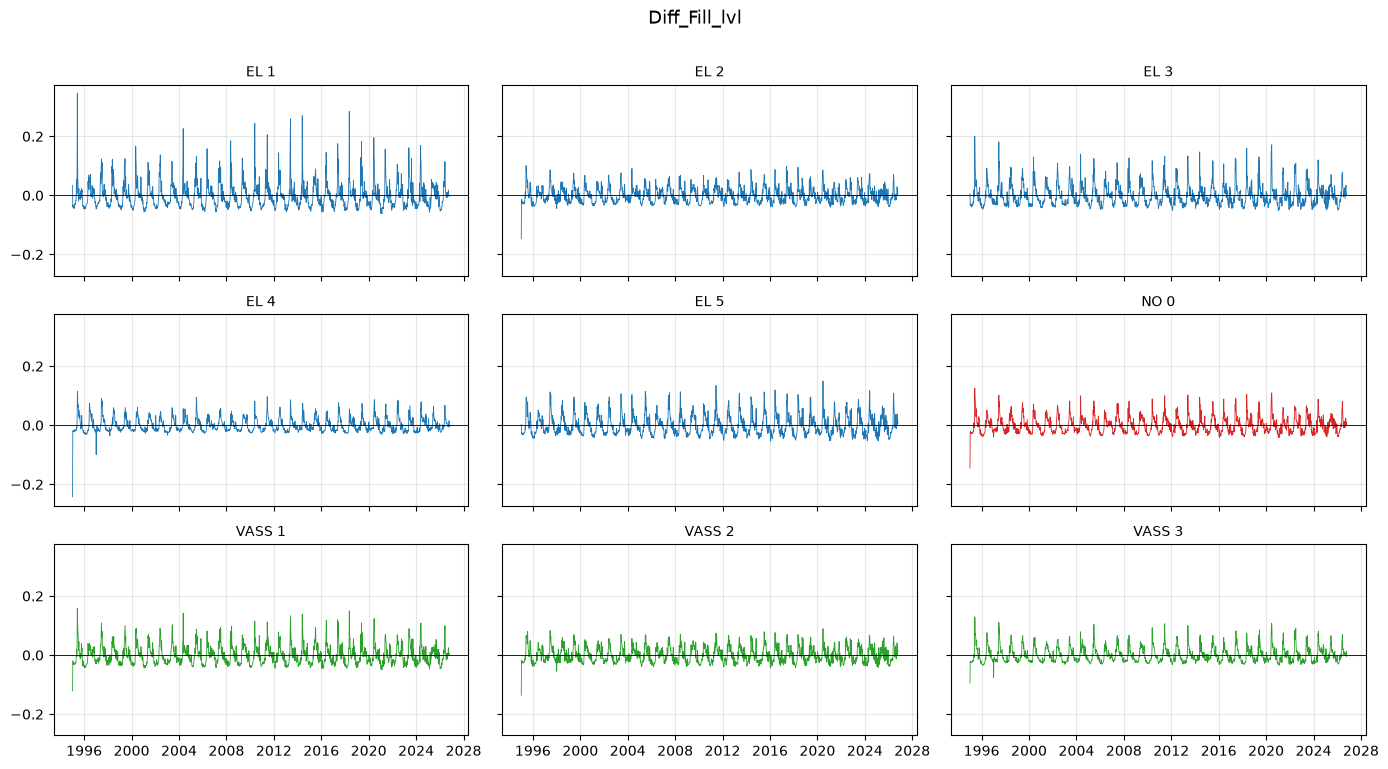

In [36]:
# Plot fill level over time (same y-axis, so the areas can be compared)
plot_by_area("Fill_lvl")

# Plot reservoir capacity over time (own y-axis for each area)
plot_by_area("Capacity_TWh", same_scale=False)

# Plot stored energy over time (own y-axis for each area)
plot_by_area("Fill_TWh", same_scale=False)

# Plot fill level from the previous week
plot_by_area("Fill_lvl_Lstweek")

# Plot weekly changes in fill level with a horizontal zero line
plot_by_area("Diff_Fill_lvl", zero_line=True)

## Inspecting/interpreting the plots
The plots show how reservoir levels and stored energy change throughout the years. This code shows five time-series plots: fill level, reservoir capacity, stored energy, fill level from the previous week, and weekly changes in fill level.However, capacity stays the same, so we use a bar plot to show it.

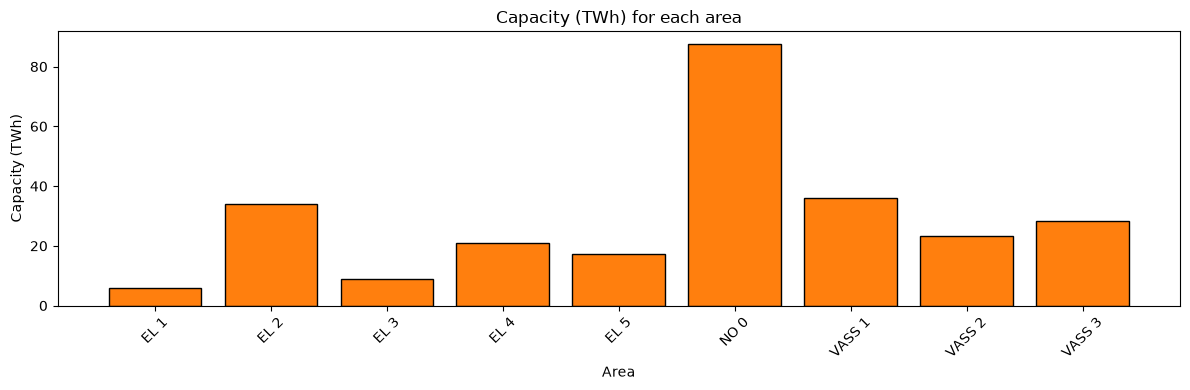

In [38]:
# Capacity for each area (the capacity is constant - a bar pr. area)
capacity = (reservoirs.groupby(["Area_type", "Area_number"])["Capacity_TWh"]
            .median()
            .reset_index())
capacity["Area"] = capacity["Area_type"] + " " + capacity["Area_number"].astype(str)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(capacity["Area"], capacity["Capacity_TWh"], color="tab:orange", edgecolor="black")
ax.set_title("Capacity (TWh) for each area")
ax.set_xlabel("Area")
ax.set_ylabel("Capacity (TWh)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Plotting all columns together 
In part 1, we plotted all the necessary numeric columns together, which made the plot hard to understand. In this assignment, we used two y-axes. The left axis shows the fill level, the previous week's fill level, and the weekly change. The right axis shows stored energy and capacity in TWh. This makes the data easier to read and compare. To save space, we only showed one area (EL1).

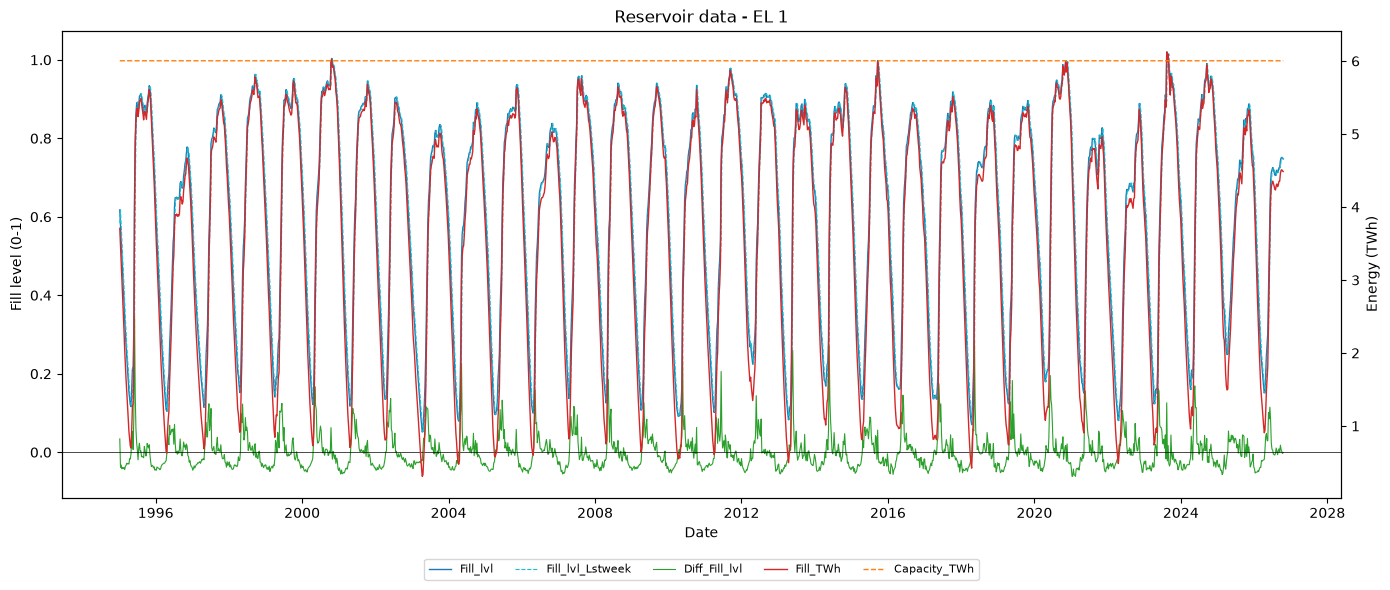

In [105]:
# Chose an area to save place
area_type = "EL"
area_number = 1

# Filter the data for the selected area
area_data = reservoirs[
    (reservoirs["Area_type"] == area_type)
    & (reservoirs["Area_number"] == area_number)
]

# Plot fill levels on the left axis
fig, ax_left = plt.subplots(figsize=(14, 6))
ax_left.plot(area_data["Date"], area_data["Fill_lvl"], color="tab:blue",
             linewidth=1.0, label="Fill_lvl")
ax_left.plot(area_data["Date"], area_data["Fill_lvl_Lstweek"], color="tab:cyan",
             linewidth=0.8, linestyle="--", label="Fill_lvl_Lstweek")
ax_left.plot(area_data["Date"], area_data["Diff_Fill_lvl"], color="tab:green",
             linewidth=0.8, label="Diff_Fill_lvl")
ax_left.axhline(0, color="black", linewidth=0.5)
ax_left.set_xlabel("Date")
ax_left.set_ylabel("Fill level (0-1)")

# Plot energy in TWh on the right axis
ax_right = ax_left.twinx()
ax_right.plot(area_data["Date"], area_data["Fill_TWh"], color="tab:red",
              linewidth=1.0, label="Fill_TWh")
ax_right.plot(area_data["Date"], area_data["Capacity_TWh"], color="tab:orange",
              linewidth=1.0, linestyle="--", label="Capacity_TWh")
ax_right.set_ylabel("Energy (TWh)")

# Combine the legends from both axes
left_lines, left_labels = ax_left.get_legend_handles_labels()
right_lines, right_labels = ax_right.get_legend_handles_labels()
ax_left.legend(left_lines + right_lines, left_labels + right_labels,
               loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, fontsize=8)

# Add a title and adjust the layout
ax_left.set_title(f"Reservoir data - {area_type} {area_number}")
fig.tight_layout()

# Display the plot
plt.show()

In [137]:
#Show the Norwegian bidding zones available in entsoe-py
from entsoe.mappings import Area

zones = [area.name for area in Area if area.name.startswith("NO")]
print(zones)

['NO_1', 'NO_1A', 'NO_2', 'NO_2_NSL', 'NO_2A', 'NO_3', 'NO_4', 'NO_5', 'NO']


The ENTSO-E API uses electricity zones. Norway has five zones, NO_1 - NO_5, which match the five electricity areas in the NVE data. In this project, we get power transfer data for NO_1-SE_3, NO_2-DK_1 and NO_4-SE_1.

In [66]:
from entsoe import EntsoePandasClient

# Reads the ENTSO-E token from a local file
token = (Path.home() / ".entsoe_token").read_text(encoding="utf-8").strip()
entsoe_client = EntsoePandasClient(api_key=token)

In [68]:
import time
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, TimestampType, DoubleType

# All times are handled in UTC
spark.conf.set("spark.sql.session.timeZone", "UTC")

# The three connections (Norway - neighbour)
connections = [("NO_1", "SE_3"), ("NO_2", "DK_1"), ("NO_4", "SE_1")]

# The period: the last two years, from October 2024 until now
period_start = pd.Timestamp("2024-10-01", tz="Europe/Oslo")
period_end = pd.Timestamp("2026-10-26", tz="Europe/Oslo")

# Schema for the Spark DataFrame
schema = StructType([
    StructField("connection", StringType(), False),
    StructField("direction", StringType(), False),
    StructField("timestamp", TimestampType(), False),
    StructField("energy_mwh", DoubleType(), True),
])


def to_rows(series, connection, direction):
    # Turn an ENTSO-E series into rows, with the time in UTC
    # The time zone is kept (UTC), so Spark does not read the times as local time
    s = series.copy()
    s.index = s.index.tz_convert("UTC")
    return [(connection, direction, ts.to_pydatetime(), float(v))
            for ts, v in s.dropna().items()]

# Fetch the flow from a to b, and try again if ENTSO-E fails
def fetch(a, b, start, end, tries=3):
    
    for attempt in range(tries):
        try:
            return entsoe_client.query_crossborder_flows(a, b, start=start, end=end)
        except Exception as error:
            print("   try", attempt + 1, "failed:", type(error).__name__)
            time.sleep(5)
    return None


# Query that counts the rows already in Cassandra
count_query = session.prepare(
    "SELECT count(*) FROM ind320.entsoe_transfers "
    "WHERE connection = ? AND timestamp >= ? AND timestamp < ? "
    "AND direction = ? ALLOW FILTERING")


def period_is_loaded(name, p_start, p_end):
    # True if both directions already have (nearly) all hours of the period
    hours = (p_end - p_start).total_seconds() / 3600
    start_utc = p_start.tz_convert("UTC").tz_localize(None).to_pydatetime()
    end_utc = p_end.tz_convert("UTC").tz_localize(None).to_pydatetime()
    for direction in ["out", "in"]:
        n = session.execute(count_query, (name, start_utc, end_utc, direction)).one()[0]
        if n < 0.9 * hours:
            return False
    return True


# Month boundaries, with the last (partial) month ending today
boundaries = list(pd.date_range(period_start, period_end, freq="MS", tz="Europe/Oslo"))
if boundaries[-1] < period_end:
    boundaries.append(period_end)

failed = []

# Loop through each connection and each month
for a, b in connections:
    name = f"{a}-{b}"
    for m_start, m_end in zip(boundaries[:-1], boundaries[1:]):

        # Skip months that are already in Cassandra
        if period_is_loaded(name, m_start, m_end):
            continue

        # Fetch both directions
        out_series = fetch(a, b, m_start, m_end)   # out of Norway
        in_series = fetch(b, a, m_start, m_end)    # into Norway
        if out_series is None or in_series is None:
            failed.append((name, str(m_start.date())))
            continue

        # Write the month to Cassandra with Spark
        rows = to_rows(out_series, name, "out") + to_rows(in_series, name, "in")
        (spark.createDataFrame(rows, schema=schema).write
            .format("org.apache.spark.sql.cassandra")
            .mode("append")
            .options(keyspace="ind320", table="entsoe_transfers")
            .save())
        print(f"{name} {m_start:%Y-%m}: {len(rows)} rows written")

print("Failed months:", failed if failed else "none")

NO_1-SE_3 2024-10: 1490 rows written
NO_1-SE_3 2024-11: 1440 rows written
NO_1-SE_3 2024-12: 1488 rows written
NO_1-SE_3 2025-01: 1488 rows written
NO_1-SE_3 2025-02: 1344 rows written
NO_1-SE_3 2025-03: 1486 rows written
NO_1-SE_3 2025-04: 1440 rows written
NO_1-SE_3 2025-05: 1488 rows written
NO_1-SE_3 2025-06: 1440 rows written
NO_1-SE_3 2025-07: 1488 rows written
NO_1-SE_3 2025-08: 1488 rows written
NO_1-SE_3 2025-09: 1716 rows written
NO_1-SE_3 2025-10: 5960 rows written
NO_1-SE_3 2025-11: 5760 rows written
NO_1-SE_3 2025-12: 5952 rows written
NO_1-SE_3 2026-01: 5952 rows written
NO_1-SE_3 2026-02: 5376 rows written
NO_1-SE_3 2026-03: 5944 rows written
NO_1-SE_3 2026-04: 5760 rows written
NO_1-SE_3 2026-05: 5952 rows written
NO_1-SE_3 2026-06: 5760 rows written
NO_1-SE_3 2026-07: 5952 rows written
NO_1-SE_3 2026-08: 5952 rows written
NO_1-SE_3 2026-09: 5760 rows written
NO_1-SE_3 2026-10: 4740 rows written
NO_2-DK_1 2024-10: 1490 rows written
NO_2-DK_1 2024-11: 1440 rows written
N

In [52]:
from pyspark.sql import functions as F

# Read the entsoe_transfers table from Cassandra and select the required columns
raw = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="entsoe_transfers")
    .load()
    .select("connection", "direction", "timestamp", "energy_mwh")
)

# Count the total number of rows in the dataset
print("Total rows in Cassandra:", raw.count())

# Group by connection and direction, then count rows and find the first and last timestamps
summary = (
    raw.groupBy("connection", "direction")
    .agg(
        F.count("*").alias("rows"),
        F.min("timestamp").alias("first_time"),
        F.max("timestamp").alias("last_time")
    )
    .orderBy("connection", "direction")
)

# Display the summary table without truncating values
summary.show(truncate=False)

Total rows in Cassandra: 302862
+----------+---------+-----+-------------------+-------------------+
|connection|direction|rows |first_time         |last_time          |
+----------+---------+-----+-------------------+-------------------+
|NO_1-SE_3 |in       |46301|2024-09-30 20:00:00|2026-10-25 12:45:00|
|NO_1-SE_3 |out      |46301|2024-09-30 20:00:00|2026-10-25 12:45:00|
|NO_2-DK_1 |in       |58829|2024-09-30 20:00:00|2026-10-25 12:45:00|
|NO_2-DK_1 |out      |58829|2024-09-30 20:00:00|2026-10-25 12:45:00|
|NO_4-SE_1 |in       |46301|2024-09-30 20:00:00|2026-10-25 12:45:00|
|NO_4-SE_1 |out      |46301|2024-09-30 20:00:00|2026-10-25 12:45:00|
+----------+---------+-----+-------------------+-------------------+



In [70]:
#Reads a timestamp and direction directly from Cassandra ( without using Spark)
row = session.execute(
    "SELECT timestamp, direction FROM ind320.entsoe_transfers "
    "WHERE connection = 'NO_1-SE_3' LIMIT 1"
).one()

# The expected first time: the start of the period (00:00 Norwegian time) in UTC
expected = period_start.tz_convert("UTC").tz_localize(None)

# Compare the timestamp in Cassandra with the expected time
print("First timestamp in Cassandra (UTC):", row.timestamp, "| direction:", row.direction)
print("Expected (UTC):", expected)
print("Equal:", row.timestamp == expected.to_pydatetime())

First timestamp in Cassandra (UTC): 2024-09-30 22:00:00 | direction: in
Expected (UTC): 2024-09-30 22:00:00
Equal: True


In [72]:
# Read the Cassandra table with Spark and select the required columns
transfers_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="entsoe_transfers")
    .load()
    .select("connection", "direction", "timestamp", "energy_mwh")
)

# Print the total number of rows in the table
print("Total rows in Cassandra:", transfers_df.count())

# Count rows and find the first and last timestamp for each connection and direction
(transfers_df.groupBy("connection", "direction")
    .agg(F.count("*").alias("row_count"),
         F.min("timestamp").alias("first_timestamp"),
         F.max("timestamp").alias("last_timestamp"))
    .orderBy("connection", "direction")
    .show(truncate=False))

Total rows in Cassandra: 302910
+----------+---------+---------+-------------------+-------------------+
|connection|direction|row_count|first_timestamp    |last_timestamp     |
+----------+---------+---------+-------------------+-------------------+
|NO_1-SE_3 |in       |46308    |2024-09-30 22:00:00|2026-10-25 14:15:00|
|NO_1-SE_3 |out      |46308    |2024-09-30 22:00:00|2026-10-25 14:15:00|
|NO_2-DK_1 |in       |58837    |2024-09-30 22:00:00|2026-10-25 14:30:00|
|NO_2-DK_1 |out      |58837    |2024-09-30 22:00:00|2026-10-25 14:30:00|
|NO_4-SE_1 |in       |46310    |2024-09-30 22:00:00|2026-10-25 14:45:00|
|NO_4-SE_1 |out      |46310    |2024-09-30 22:00:00|2026-10-25 14:45:00|
+----------+---------+---------+-------------------+-------------------+



In [76]:
# The values are power (MW), so the average over one hour gives the energy (MWh)
hourly_transfers = (
    transfers_df
    .withColumn("hour", F.date_trunc("hour", F.col("timestamp")))
    .groupBy("connection", "direction", "hour")
    .agg(F.avg("energy_mwh").alias("average_energy_mwh"))
    .orderBy("connection", "direction", "hour")
)

# Count the number of hourly records for each connection and direction
hourly_transfers.groupBy("connection", "direction").count().orderBy("connection", "direction").show()

+----------+---------+-----+
|connection|direction|count|
+----------+---------+-----+
| NO_1-SE_3|       in|18113|
| NO_1-SE_3|      out|18113|
| NO_2-DK_1|       in|18113|
| NO_2-DK_1|      out|18113|
| NO_4-SE_1|       in|18113|
| NO_4-SE_1|      out|18113|
+----------+---------+-----+



In [77]:
# Move the small hourly result to Pandas and name the energy column "mwh" (used by Streamlit)
df_hourly = hourly_transfers.toPandas().rename(columns={"average_energy_mwh": "mwh"})

# Add year, month and local time (follwing norwegian time)
df_hourly["hour"] = pd.to_datetime(df_hourly["hour"])
local = df_hourly["hour"].dt.tz_localize("UTC").dt.tz_convert("Europe/Oslo")
df_hourly["year"] = local.dt.year.astype("int64")
df_hourly["month"] = local.dt.month.astype("int64")
df_hourly["time_local"] = local.dt.tz_localize(None)

print("Rows:", len(df_hourly))
print("First hour (UTC):", df_hourly["hour"].min())
print("Last hour (UTC):", df_hourly["hour"].max())
df_hourly.head()

Rows: 108678
First hour (UTC): 2024-09-30 22:00:00
Last hour (UTC): 2026-10-25 14:00:00


,connection,direction,hour,mwh,year,month,time_local
0,NO_1-SE_3,in,2024-09-30 22:00:00,1257.0350,2024,10,2024-10-01 00:00:00
1,NO_1-SE_3,in,2024-09-30 23:00:00,1282.7600,2024,10,2024-10-01 01:00:00
2,NO_1-SE_3,in,2024-10-01 00:00:00,1225.7700,2024,10,2024-10-01 02:00:00
3,NO_1-SE_3,in,2024-10-01 01:00:00,1308.3925,2024,10,2024-10-01 03:00:00
4,NO_1-SE_3,in,2024-10-01 02:00:00,1292.7050,2024,10,2024-10-01 04:00:00


In [83]:
# Calculates the average MWh per month for each connection and direction
monthly_average_energy = (
    df_hourly.groupby(["connection", "direction", "year", "month"])["mwh"]
    .mean()
    .round(1)
)

# Displays results with connection and directions
monthly_average_energy.unstack(["connection", "direction"])

connection NO_1-SE_3        NO_2-DK_1         NO_4-SE_1       
direction         in    out        in     out        in    out
year month                                                    
2024 10        920.8   34.3      85.9  1063.0     160.0   95.6
     11        807.2  111.2      79.9  1085.3     119.5  141.3
     12        783.9  237.8     100.8  1035.0     165.9  131.9
2025 1         575.5  283.4     125.5  1022.1      93.9  108.7
     2         406.3  358.4       9.3  1173.0      38.7  102.2
     3         795.8  217.5      67.9  1200.8      75.1   56.2
     4         491.5  282.6      41.7   970.5      94.2   37.6
     5         759.8  171.7     310.6   573.2       5.2  330.4
     6         657.2  131.0     276.1   625.9      24.8  288.8
     7         733.5   78.3      40.9  1061.9       5.1  228.8
     8         604.5  126.1     127.7   763.7       4.1  161.4
     9         697.8   62.2      63.9   941.0      33.8  127.7
     10        925.8   30.6     217.9   937.6      97.0   96.7
     11        772.5  234.1     144.7   911.9      73.0  151.5
     12        956.8  264.3     142.5  1007.7     168.6   80.0
2026 1         328.5  516.2     177.0   620.1      27.3  177.9
     2         267.7  381.5     445.7   257.7      40.0  158.0
     3         936.5   34.2     588.4   542.6     270.9   49.8
     4         734.1  108.2     516.9   503.1     232.7   52.6
     5         617.7  158.0     425.5   702.5      70.4  163.2
     6         284.2  170.0     294.0   704.6      13.1  359.1
     7         908.9  170.9     452.3   595.6       6.4  362.4
     8         939.1   22.1     395.2   660.0      12.9  329.6
     9         452.4   76.1     238.3   293.1      29.6  213.7
     10        826.9   22.4     289.0   596.9      35.5  329.8

## Pie chart for the total production 
Displays a pie chart for the total production of one year from a chosen connection, where each piece of the pie is the amount in and out of Norway

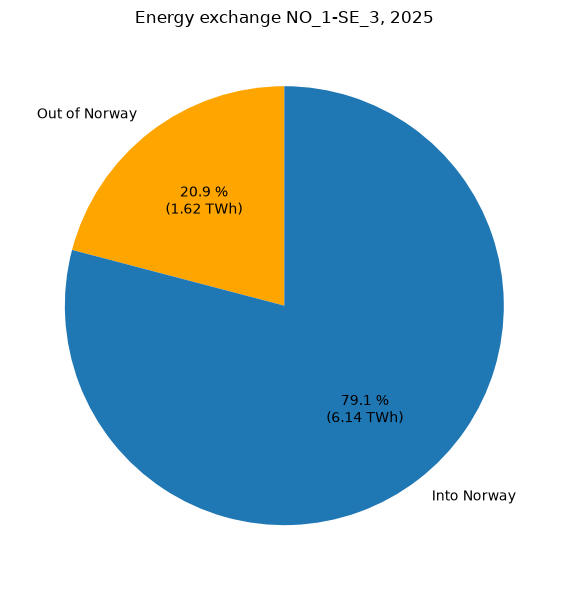

In [95]:
# Choose a connection and a year
selected_connection = "NO_1-SE_3"
selected_year = 2025

# Labels used for the directions in the legend
direction_labels = {"out": "Out of Norway", "in": "Into Norway"}

# Keeps the data to include only the selected connection and year
filtered_data = df_hourly[(df_hourly["connection"] == selected_connection) &
                          (df_hourly["year"] == selected_year)]

# Adds up the energy for each direction and converts from MWh to TWh
energy_by_direction = (filtered_data.groupby("direction")["mwh"].sum() / 1_000_000).reindex(["out", "in"])

# Plots the share of energy out of and into Norway
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(energy_by_direction,
       labels=[direction_labels[d] for d in energy_by_direction.index],
       colors=["orange", "tab:blue"],
       autopct=lambda p: f"{p:.1f} %\n({p * energy_by_direction.sum() / 100:.2f} TWh)",
       startangle=90)

# Adds title and adjust the layout
ax.set_title(f"Energy exchange {selected_connection}, {selected_year}")
plt.tight_layout()

#Display of plot
plt.show()

The pie chart shows the total power exchange on NO_1-SE_3 in 2025. 6.14 TWh flowed into Norway, while 1.62 TWh flowed out. This means about 79,1% of the power flow was into Norway, and 20,9% of the power flow out.

## Line plot for the first month of a year 
Displays a line plot for the first month of a year for a chosen connection. Make separate lines for each connection and direction.

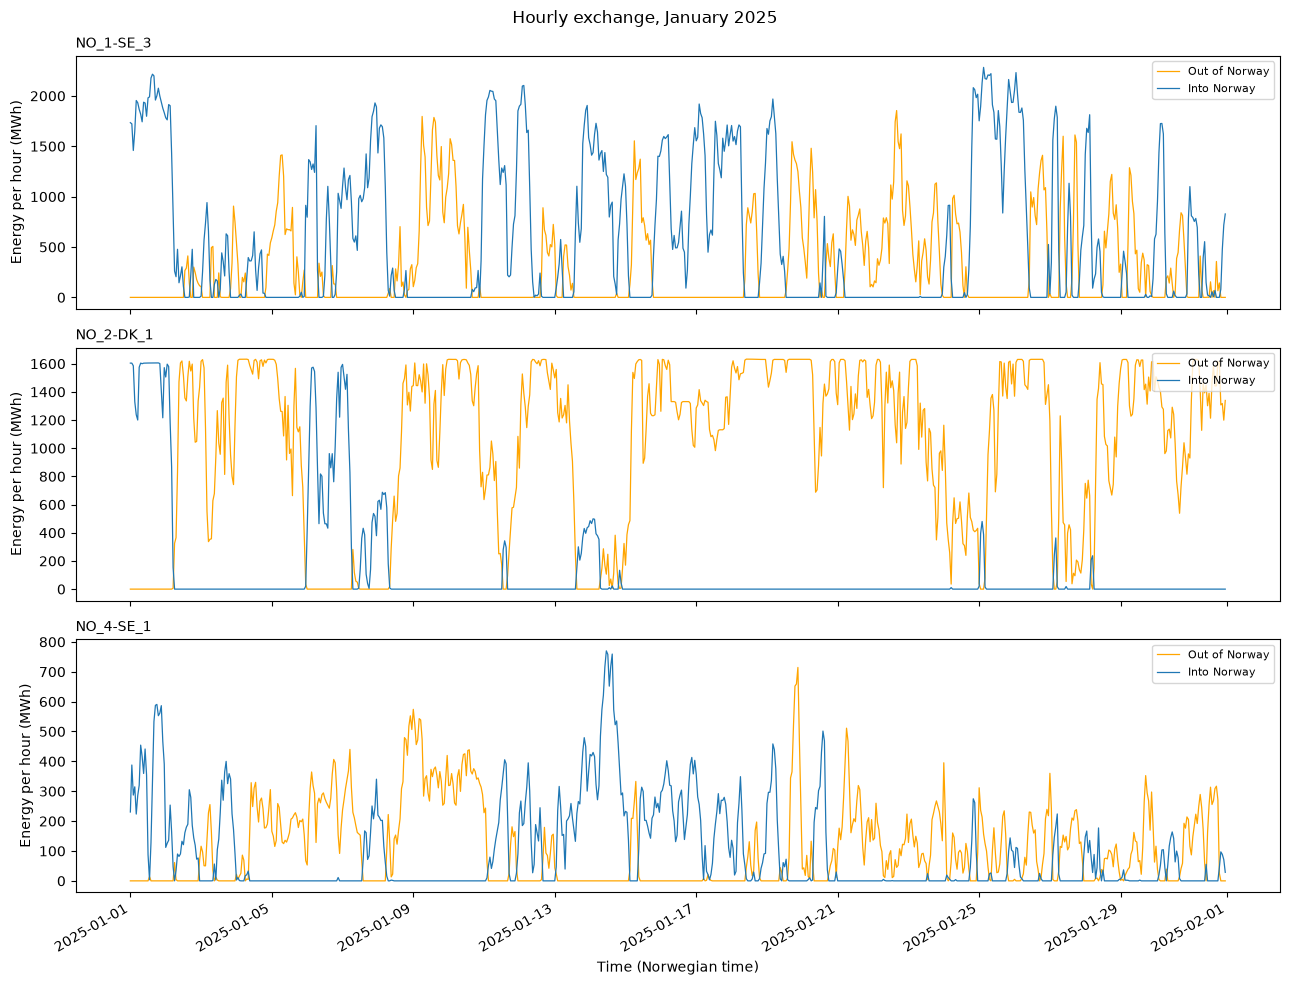

In [97]:
# Choose a year
year = 2025
# Labels used for the directions in the legend
direction_labels = {"out": "Out of Norway", "in": "Into Norway"}

# Keeps the data to include only January of the selected year
january_data = df_hourly[(df_hourly["year"] == year) & (df_hourly["month"] == 1)]

# Colours each direction (same colours as in the pie chart)
connection_names = sorted(df_hourly["connection"].unique())
direction_colors = {"out": "orange", "in": "tab:blue"}

# Plots hourly energy for each direction, one panel per connection (own y-axis in each panel)
fig, axes = plt.subplots(len(connection_names), 1, figsize=(13, 10), sharex=True, sharey=False)
for ax, name in zip(axes, connection_names):
    for direction in ["out", "in"]:
        group = january_data[(january_data["connection"] == name) &
                             (january_data["direction"] == direction)].sort_values("time_local")
        ax.plot(group["time_local"], group["mwh"], linewidth=0.9,
                color=direction_colors[direction], label=direction_labels[direction])
    ax.set_title(name, fontsize=10, loc="left")
    ax.set_ylabel("Energy per hour (MWh)")
    ax.legend(loc="upper right", fontsize=8)

# Adds title, labels and adjust the layout
fig.suptitle(f"Hourly exchange, January {year}")
axes[-1].set_xlabel("Time (Norwegian time)")
fig.autofmt_xdate()
plt.tight_layout()

#Display of plot
plt.show()

The line plot shows the power flow for each connection in January 2025, hour by hour. Each panel shows one connection, with separate lines for each direction. The direction changes often, but usually one direction has a higher flow at a time.

## Uploads to MongoDB
The data from Spark is stored in MongoDB, in a collection called entsoe_hourly. The Streamlit app uses this data from MongoDB. The code also checks that all rows are saved correctly.

In [139]:
# Select the database and collection
db = client["ind320"]
data = db["entsoe_hourly"]

# Prepare the hourly data for MongoDB
docs = (df_hourly[["connection", "direction", "hour", "mwh", "year", "month"]]
        .rename(columns={"hour": "timestamp_utc"})
        .to_dict("records"))

# Remove old data and insert the new data in batches
data.delete_many({})
for i in range(0, len(docs), 10000):
    data.insert_many(docs[i:i + 10000])

# Create an index to make queries faster
data.create_index([("connection", 1), ("year", 1), ("month", 1)])

# Check the number of documents in MongoDB
print("Documents in MongoDB:", data.count_documents({}))
print("Rows in DataFrame:", len(df_hourly))

# Calculate total energy for the selected connection and year
result = data.aggregate([
    {"$match": {"connection": selected_connection, "year": selected_year}},
    {"$group": {"_id": "$direction", "total_mwh": {"$sum": "$mwh"}}},
])

# Show the total energy for each direction in TWh
for row in result:
    print(row["_id"], round(row["total_mwh"] / 1_000_000, 2), "TWh")

Documents in MongoDB: 108678
Rows in DataFrame: 108678
in 6.14 TWh
out 1.62 TWh


## Log with a description of the work  (300–500 words)

### Notebook:
De nødvendige bibliotekene ble importert, og versjonene deres ble skrevet ut for å dokumentere arbeidsmiljøet. Spark ble satt opp med Java og Hadoop, og Cassandra ble konfigurert i Docker med databasen «ind320» og tabellen «entsoe_transfers». Forbindelsen mellom Spark og Cassandra, og til MongoDB, ble testet. Testdataene ble slettet etter at testene bekreftet at kommunikasjonen fungerte. Data fra NVE om magasinfylling ble hentet via API-et. API-et dekker hele landet, fem elspotområder og fire vassdragsområder. Dataene ble undersøkt, kolonnenavnene endret til engelsk, og det ble laget tidsserieplott og søylediagrammer med tilbakemeldingene fra del 1 i tankene. Data fra ENTSO-E for to år ble hentet for tre forbindelser mellom Norge og nabolandene, i begge retninger. Tidsstemplene ble lagret i UTC for å unngå problemer med sommertid. Etter at tidsforskjellen ble oppdaget, ble tidspunktene håndtert riktig. Spark ble brukt til å beregne gjennomsnittlig effekt per time, som gir overført energi i MWh. Det ble laget et kakediagram for å vise total energi inn og ut av Norge per år, og et linjediagram for å vise energi per time i januar. Til slutt ble timedataene («df_hourly») lagret i MongoDB, som Streamlit-appen henter dataene fra.

### GitHub:
Prosjektet ligger i GitHub under "IND320-reservoir". Part 2 ble først lagt rett inn på main-branchen, men siden oppgaven krever bruk av branches, ble det laget en egen branch, "IND320_part2", med den ferdige notebooken og noen mindre oppdateringer, bl.a. ble "reservoirs.csv" slettet, siden dataene nå hentes fra NVE-API-et. Branchen ble deretter slått sammen med main. "app.py" er hovedfilen til Streamlit, "nve_data.py" inneholder funksjonene som henter dataene fra NVE, og "requirements.txt" inneholder bibliotekene som trengs. I mappen "pages" ligger "1_Front.py" som er forsiden, "2_Data_table.py", "3_Visualisation.py" og "5_Energy_Flow.py".

### Streamlit:

Appen ble oppdatert slik at dataene hentes direkte fra NVE-API-et. På "Data table"-siden velger radioknapper områdetype (EL, NO eller VASS), og en slider bestemmer hvilken periode som lastes ned. Tabellen har rad pr. område med siste verdier og et lite linjediagram (LineChartColumn) for hver variabel. "Visualisation"-siden har de samme valgene, og brukeren kan velge en kolonne, eller alle kolonnene skalert mellom 0 og 1, og får en linje pr område. "Energy Flow"-siden leser ENTSO-E-dataene fra MongoDB og er delt i to kolonner. Til venstre, radioknapp forbindelse og en nedtrekksliste år, og et kakediagram som viser energien inn til og ut av Norge. Til høyre, kan man velge hvilke måneder som skal vises, og linjediagrammet viser en linje for hver forbindelse og retning.

# KI-Erklæring
I denne oppgaven har KI-verktøyene ChatGPT og Claude blitt benyttet i tråd med NMBUs retningslinjer for K3. Mer spesifikt ble de brukt til å kontrollere egen kode ved å spørre om koden var korrekt og oppfylte kravene i oppgaven. Når det ble identifisert feil, ble det generert utdypende forslag og forklaringer på hvordan feilene kunne rettes. KI ble hovedsakelig brukt til å forstå programmeringskonsepter, feilsøke, forbedre kodestrukturen og forklare hvordan applikasjonene fungerer. Forslagene ble brukt til å rette feil, forbedre og forståelse av løsningene.